# From Markov chains to Monte Carlo sampling

How can a dependent sequence of random states help us compute a probability or an integral? We first simulate a three-state weather model with a known transition matrix. We then construct a continuous-state chain whose stationary distribution is a chosen target density using **Metropolis–Hastings**.

## Lecture goals

- Distinguish a random state, its probability distribution, and an empirical frequency.
- Use a transition matrix to propagate probabilities and find a stationary distribution.
- Derive the Metropolis–Hastings acceptance rule and explain why rejections remain in the chain.
- Interpret burn-in, autocorrelation, and the effect of proposal width on Monte Carlo estimates.

Run the cells in order using Python 3 with NumPy, Matplotlib, and SciPy. The setup cell seeds NumPy's random generator with `42`; reproducing the saved sequence requires the same execution order and a compatible software environment. Rerunning a later sampling cell advances the random stream rather than resetting it. The final experiment uses 500,000 proposals and takes longer than the preceding examples.


In [9]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [10, 6]
np.random.seed(42)

## 1. A Markov model for weather

Let $X_t$ denote the weather on day $t$, with state space

$$\mathcal S=\{0,1,2\}=\{\text{sunny},\text{cloudy},\text{rainy}\}.$$

The **Markov property** states that the current state contains all the information from the past needed to predict the next state:

$$\Pr(X_{t+1}=j\mid X_t=i,X_{t-1},\ldots,X_0)
=\Pr(X_{t+1}=j\mid X_t=i).$$

It does not say that successive states are independent. This example is also **time-homogeneous**: the transition probabilities do not depend on $t$. It is a simplified model, not an empirical weather forecast.

We will distinguish the realized state $X_t$, a single integer, from the probability row vector

$$\mathbf p_t=\bigl(\Pr(X_t=0),\Pr(X_t=1),\Pr(X_t=2)\bigr).$$

Starting in sunny weather means $X_0=0$ and $\mathbf p_0=(1,0,0)$.

In [10]:
# Allowed states
state_space = ("sunny", "cloudy", "rainy")

### Transition probabilities and the row-vector convention

The entry $P_{ij}$ is the probability of moving **from row $i$ to column $j$**:

$$P_{ij}=\Pr(X_{t+1}=j\mid X_t=i),\qquad
P=\begin{pmatrix}0.6&0.3&0.1\\0.3&0.4&0.3\\0.2&0.3&0.5\end{pmatrix}.$$

Each row sums to one. For example, after a sunny day the probabilities for the next day are $(0.6,0.3,0.1)$. Probability distributions evolve according to

$$\mathbf p_{t+1}=\mathbf p_tP,\qquad \mathbf p_t=\mathbf p_0P^t.$$

Starting sunny, $\mathbf p_0=(1,0,0)$, so after one transition,

$$\mathbf p_1=\mathbf p_0P=(0.6,0.3,0.1).$$

After a second transition, multiply this row vector by $P$:

$$\mathbf p_2=\mathbf p_1P
=(0.6,0.3,0.1)
\begin{pmatrix}
0.6&0.3&0.1\\
0.3&0.4&0.3\\
0.2&0.3&0.5
\end{pmatrix}.$$

For each destination, sum over the three possible intermediate weather states:

$$\begin{aligned}
p_2(\text{sunny})
&=0.6(0.6)+0.3(0.3)+0.1(0.2)\\
&=0.36+0.09+0.02=0.47,\\[4pt]
p_2(\text{cloudy})
&=0.6(0.3)+0.3(0.4)+0.1(0.3)\\
&=0.18+0.12+0.03=0.33,\\[4pt]
p_2(\text{rainy})
&=0.6(0.1)+0.3(0.3)+0.1(0.5)\\
&=0.06+0.09+0.05=0.20.
\end{aligned}$$

For example, the term $0.3(0.3)$ in the rainy probability represents the path sunny $\to$ cloudy $\to$ rainy.

Thus

$$\boxed{\mathbf p_2=(0.47,0.33,0.20)},\qquad 0.47+0.33+0.20=1.$$


In [11]:
# Transition matrix
transition_matrix = np.array([
    [0.6, 0.3, 0.1],
    [0.3, 0.4, 0.3],
    [0.2, 0.3, 0.5]
])

# note that the sum of each row in the transition matrix must be 1

### Simulate one trajectory

The call to `np.random.choice` draws from the row corresponding to the latest state. This produces one random trajectory, rather than explicitly propagating $\mathbf p_t$.

With `n_steps = 20000`, the list contains **20,001 recorded states**, including $X_0$. The following plot uses prefixes of this list to estimate occupation probabilities. Many observations along one dependent trajectory can estimate long-run averages when the chain has the required ergodic properties.

In [12]:
# Run the Markov chain for a while

n_steps = 20000
states = [0]
for i in range(n_steps):
    states.append(np.random.choice((0, 1, 2), p=transition_matrix[states[-1]]))
states = np.array(states)

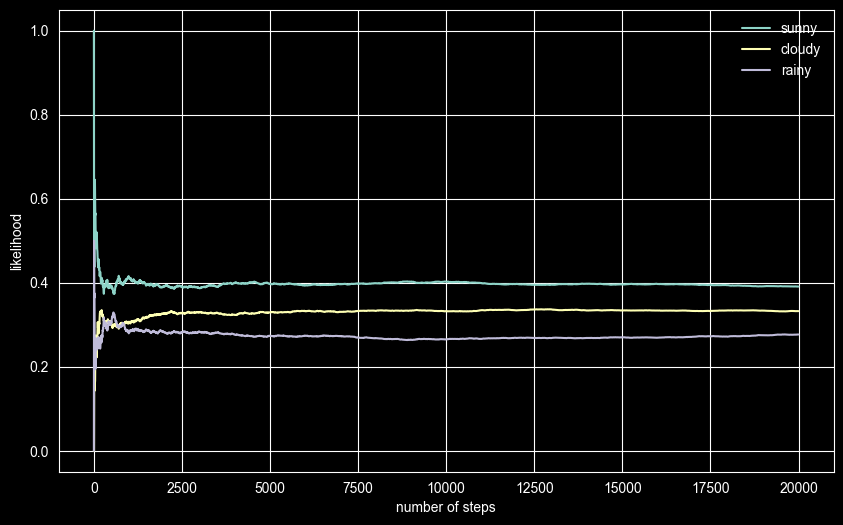

In [13]:
# Plot the states

#def despine(ax, spines=('top', 'left', 'right')):
#    for spine in spines:
#        ax.spines[spine].set_visible(False)

fig, ax = plt.subplots()
width = 1000
offsets = range(1, n_steps, 5)
for i, label in enumerate(state_space):
    ax.plot(offsets, [np.sum(states[:offset] == i) / offset
            for offset in offsets], label=label)
ax.set_xlabel("number of steps")
ax.set_ylabel("likelihood")
ax.legend(frameon=False)
#despine(ax, ('top', 'right'))
plt.show()

### Why do the three curves settle at these particular values?

Imagine watching the weather for many days and keeping three running counters. Each day, you increase the counter for the weather you observed. The plot divides each counter by the total number of recorded days. It answers **“What fraction of our time have we spent in each state?”**, not “What will the weather definitely be tomorrow?”

Mathematically, the plotted **occupation fraction** is

$$\hat\pi_j(N)=\frac{1}{N}\sum_{t=0}^{N-1}\mathbf 1\{X_t=j\}.$$

The indicator is one when the observed weather is $j$ and zero otherwise. The plot's label “likelihood” means an empirical probability here; “occupation fraction” would be more precise.

### The transition rules favor some states over others

Three possible states do not imply that each must occupy one third of the trajectory. The transition matrix determines how easily the chain enters each state and how long it tends to remain there.

For example, sunny weather persists with probability $0.6$, whereas rainy weather persists with probability $0.5$. From cloudy weather, sunny and rainy are equally likely next states, but a rainy day changes directly to sunny with probability $0.2$, while a sunny day changes directly to rainy with probability only $0.1$. These rules help explain why sunny days are more common than rainy days in the long run. Looking only at the diagonal entries would miss these arrivals from other states.

### A balance of arrivals and departures

Picture a large collection of independent copies of this weather model, with some currently sunny, some cloudy, and some rainy. Every time step redistributes the copies according to the rows of $P$.

A stable distribution is reached when the **total probability entering each state balances the total probability leaving it**. Individual copies keep changing weather, but the overall proportions no longer change. For sunny weather, this balance is

$$\underbrace{0.4\pi_s}_{\text{leave sunny}}
=\underbrace{0.3\pi_c+0.2\pi_r}_{\text{arrive from cloudy or rainy}}.$$

The factor $0.4$ is $1-0.6$: the probability of leaving sunny weather. This is a balance of total flows; it does not require the flow between every pair of states to balance separately.

### Why cloudy settles at exactly one third

Cloudy weather has a particularly simple rule. From either non-cloudy state, the probability of becoming cloudy is $0.3$. From cloudy weather, the probability of leaving is $0.6$. Therefore, at equilibrium,

$$0.6\pi_c=0.3 \pi_s + 0.3 \pi_r = 0.3(\pi_s + \pi_r) = 0.3(1-\pi_c)
\quad\Longrightarrow\quad
\boxed{\pi_c=\frac13}.$$

Once we know $\pi_c=1/3$, the remaining probability is shared by sunny and rainy weather:

$$\pi_r=\frac23-\pi_s.$$

Insert this into the sunny arrival–departure balance:

$$\begin{aligned}
0.4\pi_s&=0.3\left(\frac13\right)+0.2\left(\frac23-\pi_s\right),\\
0.6\pi_s&=\frac1{10}+\frac2{15}=\frac7{30},\\
\pi_s&=\frac7{18},\qquad
\pi_r=\frac23-\frac7{18}=\frac5{18}.
\end{aligned}$$

Thus the transition rules predict

$$\boxed{(\pi_s,\pi_c,\pi_r)\approx(0.3889,0.3333,0.2778).}$$

As a check on the physical picture, at these proportions the probability leaving sunny is $0.4(7/18)=7/45$, and the probability arriving is $0.3(1/3)+0.2(5/18)=7/45$. Sunny's share therefore neither grows nor shrinks.

### Why one trajectory reveals that balance

The collection of copies explains a probability distribution. Our plot instead follows **one copy over time**. The connection is that this finite chain can move between every pair of states and cannot get trapped permanently in a separate part of the state space. Its long-run time fractions therefore approach the same stationary proportions. This is the ergodic connection between a time average and a stationary probability.

Beginning with a sunny day strongly affects the first few observations. As the chain explores all three states, the influence of that initial choice fades. The weather continues to fluctuate forever, but the accumulated fractions become increasingly stable. Each newly observed day changes a running fraction by

$$\hat\pi_j(N+1)-\hat\pi_j(N)
=\frac{\mathbf 1\{X_N=j\}-\hat\pi_j(N)}{N+1}.$$

Early observations can move a curve substantially; late observations have much less leverage. Averaging smooths the curves, while the chain's long-run behavior determines **which values** they approach. Smoothness alone would not prove that a poorly exploring chain had reached the correct proportions.

The approach is not necessarily monotonic, and finite runs will not give the exact fractions. Successive weather states are correlated, so fluctuations do not behave exactly like those from independent daily draws.

### What this plotting code does—and does not—do

The weather plot averages the entire prefix of the trajectory; it does not discard an initial burn-in segment. Selecting `offsets` in steps of five only draws fewer points on the graph: every plotted estimate still includes all preceding states. It neither thins the trajectory nor removes its correlations.

**Discussion:** If we start rainy instead of sunny, which part of the plot should change most? Should the long-run fractions change? What transition rules would need to change if we wanted rainy weather to dominate instead?


### Watch the individual weather states

The occupation plot summarizes the past; a **trace plot** shows the actual state $X_t$ at each iteration. The next cell displays the first 200 transitions, including the initial state at $t=0$, from the **same simulated trajectory**.

Each dot is one recorded state. Horizontal stretches indicate consecutive observations of the same weather; vertical steps indicate a change. The connecting steps are a visual guide: the chain does not pass through intermediate weather categories between observations.

Change `trace_start` to inspect a later part of the trajectory, or increase `trace_transitions` to display a longer interval. Showing all 20,000 transitions at once makes individual changes hard to distinguish.

**Compare the two plots:** the occupation fractions become stable, but the weather keeps switching. Equilibrium is a stable distribution of time spent in the states, not a trajectory that stops moving. Compare an early window with one starting at iteration 10,000; short windows need not have exactly the long-run occupation fractions.


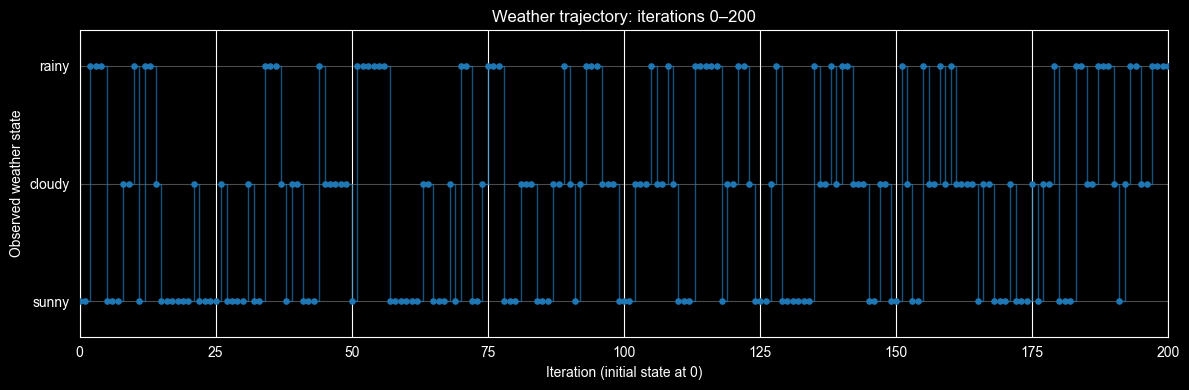

In [14]:
# Display recorded states without rerunning the simulation.
trace_start = 0
trace_transitions = 200
if not 0 <= trace_start < len(states) - 1:
    raise ValueError("trace_start must leave at least one recorded transition.")
if trace_transitions < 1:
    raise ValueError("trace_transitions must be at least 1.")
trace_stop = min(trace_start + trace_transitions + 1, len(states))
trace_iterations = np.arange(trace_start, trace_stop)

fig, ax = plt.subplots(figsize=(12, 4))
ax.step(trace_iterations, states[trace_start:trace_stop], where="post",
        color="tab:blue", linewidth=1, alpha=0.7)
ax.scatter(trace_iterations, states[trace_start:trace_stop],
           color="tab:blue", s=14, zorder=3)
ax.set_yticks(np.arange(len(state_space)))
ax.set_yticklabels(state_space)
ax.set_ylim(-0.3, len(state_space) - 0.7)
ax.set_xlim(trace_iterations[0], trace_iterations[-1])
ax.set_xlabel("Iteration (initial state at 0)")
ax.set_ylabel("Observed weather state")
ax.set_title(f"Weather trajectory: iterations {trace_start}–{trace_stop - 1}")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()


## 2. Stationarity and convergence

A **stationary distribution** is a probability row vector $\boldsymbol\pi$ satisfying

$$\boldsymbol\pi P=\boldsymbol\pi,
\qquad \sum_j\pi_j=1,\qquad \pi_j\geq0.$$

If $X_0$ has this distribution, every $X_t$ has the same marginal distribution. Individual trajectories still move between states: stationarity describes an unchanging **distribution**, not an unchanging weather state.

For this matrix, the balance equations include

$$\begin{aligned}
\pi_s&=0.6\pi_s+0.3\pi_c+0.2\pi_r,\\
\pi_c&=0.3\pi_s+0.4\pi_c+0.3\pi_r,\\
\pi_r&=0.1\pi_s+0.3\pi_c+0.5\pi_r.
\end{aligned}$$

Together with normalization, these give

$$\boxed{\boldsymbol\pi=\left(\frac7{18},\frac13,\frac5{18}\right)
\approx(0.3889,0.3333,0.2778).}$$

Every entry of $P$ is positive, so every state can reach every other state (**irreducibility**). Its positive self-transition probabilities also make it **aperiodic**. For a finite chain, these properties ensure a unique stationary distribution and convergence to it from any initial distribution:

$$P^n\longrightarrow
\begin{pmatrix}\boldsymbol\pi\\\boldsymbol\pi\\\boldsymbol\pi\end{pmatrix}.
$$

A row-stochastic matrix alone is not enough: a chain can have disconnected classes or alternate periodically between states. The next cell computes $P^{100}$. Each row gives the distribution after 100 transitions from a different starting state; the nearly identical rows approximate $\boldsymbol\pi$. Despite its variable name, `steady_state` is a matrix, not a single state or probability vector.

In [15]:
import numpy.linalg as linalg

steady_state = linalg.matrix_power(transition_matrix, 100)

print(steady_state)

[[0.38888889 0.33333333 0.27777778]
 [0.38888889 0.33333333 0.27777778]
 [0.38888889 0.33333333 0.27777778]]


## 3. Metropolis–Hastings: making a random walk spend its time in the right places

### Why is it called Metropolis–Hastings?

The name comes from the history of the method. In 1953, Nicholas Metropolis, Arianna Rosenbluth, Marshall Rosenbluth, Augusta Teller, and Edward Teller published an algorithm that used random proposed moves and an acceptance rule to sample a desired distribution. The original method used symmetric proposals: proposing a move from $x$ to $y$ was just as likely as proposing the reverse move from $y$ to $x$. This is the type of proposal we use in this notebook.

In 1970, W. K. Hastings generalized the acceptance rule so that the proposal mechanism did not have to be symmetric. The more general method is therefore called the **Metropolis–Hastings algorithm**. The name combines the earlier Metropolis algorithm with Hastings's generalization, although several researchers contributed to the original work.

### Start with what we learned from the weather model

Our weather simulation kept changing state, but over many steps it spent predictable fractions of its time in sunny, cloudy, and rainy weather. The transition rules determined those fractions.

Now turn that question around: **could we choose the movement rules, knowing only the measured values of the various $\pi$ values, so that our simulation spends its time in a way that is
 consistent with these values?**

As we said, calculating the transition matrix from first principles may be super-hard, or even impossible!  So, if we could figure out a way to do this, it would be a huge advantage!

To investigate this problem, we will use a different example, which is one-dimensional RANDOM WALK.  This is classic
and simple:  from a given position, move by some amound in one direction or the other.  We are going
to specify, though, that if we measure the actual position, we will find a probability distribution
that corresponds to a Gaussian, i.e. a bell-curve centered at zero.

In other words, we need a walker that visits the region near zero often, visits regions farther away less often, and explores both sides. Metropolis–Hastings gives us a recipe for that walk.

### Think of the curve's height as a score

Imagine drawing the desired bell-shaped curve above a number line. At any position, the height of the curve gives that position a score. Positions near the center have high scores; positions far from the center have low scores.

Our goal is not to find the highest point and stay there. Our goal is to collect positions whose histogram has the shape of the curve. For equal-width intervals, a region where the curve is roughly twice as high should receive roughly twice as many visits over a sufficiently long run.

We must know how to calculate the score at a proposed position (and we do, because we know
the equation of a Gaussian). What we may not know is how to generate random positions with the desired frequencies directly. Knowing how high a curve is at a point is a different task from drawing random samples from the whole curve.

### One step of the walk

For the example in this notebook, use the following rule:

1. **Suggest a move.** Choose a nearby position randomly, with equal opportunity to move left or right.
2. **Compare scores.** Evaluate the curve's height at the current and suggested positions.
3. **Decide whether to move.** If the suggested position has an equal or higher score, accept it. If its score is lower, accept it only some of the time.
4. **Record where you are.** Record the new position if you moved, or record the current position again if you stayed.

Then repeat. A suggested move is called a **proposal**. Accepting or rejecting it is simply deciding whether the walker takes that step.

### How often should we accept a lower score?

Use the ratio of the two scores:

$$\text{chance of accepting a lower-score move}
=\frac{\text{score at suggested position}}{\text{score at current position}}.$$

For example, suppose the current score is 8 and the suggested score is 2. Accept that move with probability $2/8=1/4$. You can implement this by drawing a random number between zero and one: move if the number is below 0.25; otherwise stay where you are.

In the reverse situation, moving from score 2 to score 8, always accept. There is no need to turn the ratio 4 into a probability: moves to higher scores are accepted automatically.

This simple ratio works for the proposal used here because a move and its reverse are equally likely to be suggested. If the proposal itself favors one direction over the reverse, the general Metropolis–Hastings method needs an additional correction. We do not need that correction for this notebook's symmetric random steps.

### Why does this produce the right pattern of visits?

Consider a simplified two-position example. Position A has score 8, and position B has score 2. Suppose that from either position, we always propose moving to the other one.

- From A, only one quarter of the proposals to B succeed. The walker often stays at A.
- From B, every proposal to A succeeds. The walker leaves B immediately.

Now imagine 80 walkers at A and 20 at B. In one step, we expect $80\times1/4=20$ walkers to leave A, and all 20 walkers at B to return to A. The numbers exchanged balance, so the expected totals remain 80 and 20.

That is the key idea: **the high-score position gets more visits because it is easier to enter and harder to leave.** Here it gets four times the share of recorded observations, matching the score ratio $8:2$.

On a continuous number line, the same idea applies to visits within small equal-width intervals. Random proposals explore the line, while the acceptance rule adjusts how readily the walker moves into and out of different regions. Given enough time to explore, the recorded positions build up the desired histogram. A short run may still give a poor approximation.

### Why allow moves away from the peak?

If we accepted only moves to higher scores, we would be climbing a hill. Once near the top, we would spend almost all our time there. That would help locate a maximum, but it would not reproduce the full bell-shaped distribution.

Occasionally accepting lower-score moves lets the walker visit the sides and tails as well. Those regions should be visited less often, not excluded altogether.

This is an important difference from the genetic-algorithm example: there we wanted a high-scoring solution; here we want a representative collection of positions.

### Why record a position again after a rejection?

A rejection means that one more step has passed while the walker stayed in the same place. That time counts.

In our two-position example, the repeated records at A are exactly what give A its larger share. If we kept only successful moves, the saved positions would alternate between A and B, making the two positions appear equally common. We would lose the intended four-to-one ratio.

The same principle applies to the code below: **every iteration adds one state to the chain, whether the proposal is accepted or rejected.** Repeated values are part of the answer, not duplicate data to remove.

### Why relative scores are enough

We do not need scores that already add up, or integrate, to one. Multiplying every score by the same positive number leaves every acceptance decision unchanged:

$$\frac{2}{8}=\frac{20}{80}=\frac{200}{800}.$$

This is one reason the method is useful. We can sometimes calculate relative plausibility easily even when turning those scores into a fully normalized probability distribution is difficult.

### Connect the idea to the code

The following cells supply the three ingredients: a function that scores a position, a function that proposes a nearby position, and a function that decides whether to accept the move. The scoring function uses logarithms for numerical convenience; the idea remains the same comparison of two curve heights.

**Before running:** If nearly every proposal is accepted, does that necessarily mean the walker explores quickly? What if each proposed step is extremely small? Keep this question in mind when we compare step sizes.


## 4. A Gaussian target in log form

We now want to construct a Markov chain whose states behave like samples from a standard Gaussian distribution. In this section, each state is a single real number $x$. The target probability density is

$$\pi(x)=\frac{1}{\sqrt{2\pi}}e^{-x^2/2}.$$

Here, $X$ denotes a random variable with this distribution, while $x$ denotes one possible value of $X$. Later, $X_t$ will denote the state of the Markov chain at iteration $t$.

The density is largest near $x=0$ and becomes smaller as $|x|$ increases. Therefore, a successful chain should spend most of its time near zero, while still occasionally visiting values farther away.

The factor $1/\sqrt{2\pi}$ normalizes the density so that its total area is one. The Metropolis--Hastings algorithm does not need this constant because it cancels when two density values are compared. We can therefore work with the **unnormalized target density**

$$\tilde\pi(x)=e^{-x^2/2}.$$

The tilde distinguishes this unnormalized function from the normalized density $\pi(x)$. Both functions have exactly the same shape; they differ only by the constant factor $1/\sqrt{2\pi}$.

Instead of returning $\tilde\pi(x)$ itself, the next function returns its logarithm:

$$\ell(x)=\log\tilde\pi(x)=-\frac{x^2}{2}.$$

Logarithms turn ratios of densities into differences and are more numerically stable when probabilities are very small. For example, at $x=2$, the function returns $\ell(2)=-2$, corresponding to the unnormalized density $\tilde\pi(2)=e^{-2}$.  Basically, what we are doing here is turning a likelihood ($\tilde\pi$) into a log-likelihood, as we have talked about earlier in
the course!

For a standard Gaussian, the known benchmarks are $\mathbb E[X]=0$ and $\operatorname{Var}(X)=1$. A Gaussian is easy to sample directly, but we use it here because these known answers let us check whether the MCMC method is working correctly.

In [16]:
def log_prob(x):
    return -np.sum(x**2) / 2.0

# This is the log of the unnormalized standard Gaussian density.

### A symmetric random-walk proposal

Suppose the chain is currently at $X_t=x$. Before deciding where the chain will go next, we generate a **proposed** position $Y$ by adding a random displacement to the current position:

$$Y=x+\varepsilon,\qquad
\varepsilon\sim\mathrm{Uniform}(-s/2,s/2).$$

The parameter $s$, called `stepsize` in the code, is the full width of the proposal interval. For example, if `stepsize = 3`, then $\varepsilon$ is chosen uniformly between $-1.5$ and $+1.5$. Thus, if the current position is $x=2$, the proposed position can be anywhere between $0.5$ and $3.5$.

The proposal $Y$ does not automatically become the next state. The Metropolis--Hastings acceptance step will decide whether to move to the proposed value or remain at the current value:

$$X_{t+1}=\begin{cases}
Y, & \text{if the proposal is accepted},\\
X_t, & \text{if the proposal is rejected}.
\end{cases}$$

The notation $q(y\mid x)$ describes the **proposal probability density**: it tells us how readily the proposal mechanism generates the candidate value $y$ when the current position is $x$. For this uniform proposal,

$$q(y\mid x)=\begin{cases}
1/s, & |y-x|\leq s/2,\\
0, & |y-x|>s/2.
\end{cases}$$

Our proposal is symmetric: proposing a move from $x$ to $y$ is just as likely as proposing the reverse move from $y$ to $x$. In symbols, $q(y\mid x)=q(x\mid y)$. Because these two proposal densities are equal, they cancel from the Metropolis--Hastings acceptance ratio used in the next step.

In [17]:
# Define the proposal distribution

def proposal(x,stepsize):
    return np.random.uniform(low=x-0.5*stepsize, high=x+0.5*stepsize, size=x.shape)

### Deciding whether to accept the proposal

The proposal mechanism gives us a candidate position $Y=y$, but we still need to decide whether it becomes the next state $X_{t+1}$. The Metropolis--Hastings rule makes this decision by comparing the target density at the proposed position with the target density at the current position.

In general, the acceptance probability also accounts for the proposal densities $q(y\mid x)$ and $q(x\mid y)$:

$$\alpha(x,y)=\min\left\{1,
\frac{\tilde\pi(y)q(x\mid y)}{\tilde\pi(x)q(y\mid x)}\right\}.$$

Our proposal is symmetric, so $q(y\mid x)=q(x\mid y)$. We can see directly in the fraction that these equal factors cancel. The acceptance probability therefore reduces to

$$\alpha(x,y)=\min\left\{1,\frac{\tilde\pi(y)}{\tilde\pi(x)}\right\}.$$

The symbol $\alpha(x,y)$ means the probability of accepting a proposed move from $x$ to $y$. The ratio compares how strongly the target distribution favors the two positions. The normalization constant is not needed because it would appear in both the numerator and denominator and cancel.

There are two cases:

1. If $\tilde\pi(y)\geq\tilde\pi(x)$, then the proposed position has at least as much target density as the current position. The ratio is at least one, so $\alpha(x,y)=1$ and the move is always accepted.
2. If $\tilde\pi(y)<\tilde\pi(x)$, then the proposed position has lower target density. The ratio is between zero and one, so the move is accepted only some of the time.

To make the random decision, the algorithm draws

$$u\sim\mathrm{Uniform}(0,1)$$

and accepts the proposal when $u<\alpha(x,y)$. For example, if $\alpha(x,y)=0.25$, the move is accepted whenever the random number $u$ falls below $0.25$. Over many such proposals, this happens about 25% of the time. If the proposal is rejected, the chain does not disappear or try again immediately; it records the current position again, so $X_{t+1}=X_t$.

For our Gaussian target, the code stores the log of the unnormalized density,

$$\ell(x)=\log\tilde\pi(x).$$

Using the identity $e^{a-b}=e^a/e^b$, the density ratio can be calculated from a difference of log densities:

$$\frac{\tilde\pi(y)}{\tilde\pi(x)}
=\exp\bigl[\ell(y)-\ell(x)\bigr].$$

Thus the acceptance probability used by the code is

$$\boxed{\alpha(x,y)=\min\left\{1,\exp\bigl[\ell(y)-\ell(x)\bigr]\right\}.}$$

As a concrete example, suppose the chain is at $x=0$ and proposes $y=2$. Then

$$\ell(0)=0,\qquad \ell(2)=-2,$$

so

$$\alpha(0,2)=e^{-2}\approx0.1353.$$

The move is therefore accepted about 13.5% of the time. In the reverse direction, from $x=2$ to $y=0$, the density increases, so the move is accepted with probability one.

It is important that moves to lower-density positions are sometimes accepted. If the chain accepted only moves toward higher density, it would eventually become trapped near the peak at $x=0$. It would locate the maximum of the Gaussian rather than sample the entire Gaussian distribution. Occasional moves away from the peak allow the chain to explore the tails in the correct proportions.

**Numerical note.** The current code directly exponentiates the log-density difference. For more extreme distributions, a safer equivalent is to compare logarithms and accept when

$$\log u<\min\{0,\ell(y)-\ell(x)\}.$$

This avoids numerical overflow when the log-density difference is very large.

In [18]:
# Define the acceptance probability

def p_acc_MH(x, x_new, log_prob):
    p_acc = np.exp(log_prob(x_new) - log_prob(x))
    return np.minimum(1, p_acc)

### One sampling step and a complete chain

`sample_MH` returns both an acceptance flag and the next state. On rejection, it returns `x_old`; `build_MH_chain` appends that repeated state just as it appends an accepted proposal.

After $T$ proposals, `chain` contains $T+1$ states including the initial state. The reported acceptance rate is

$$\hat a=\frac{\text{number of accepted proposals}}{T}.$$

Acceptance rate describes the moves, not the fraction of samples that are “correct.” All recorded states, including rejections, belong to the trajectory.

In [19]:
# Define the Metropolis-Hastings sampling step

def sample_MH(x_old, log_prob, stepsize):
    x_new = proposal(x_old, stepsize)
    accept = np.random.rand() < p_acc_MH(x_old, x_new, log_prob)
    if accept:
        return accept, x_new
    else:
        return accept, x_old

In [20]:
def build_MH_chain(init, stepsize, n_total, log_prob):

    n_accepted = 0
    chain = [init]

    for _ in range(n_total):
        accept, state = sample_MH(chain[-1], log_prob, stepsize)
        chain.append(state)
        n_accepted += accept

    acceptance_rate = n_accepted / float(n_total)

    return chain, acceptance_rate

## 5. Run and compare with the target density

We begin at $X_0=2$, use proposal width $s=3$, and make 10,000 proposals. The result contains 10,001 states. The following unpacking converts one-element state arrays to scalar values for display.

Inspect repeated values as well as changing ones: repeated values are expected whenever a proposal is rejected. The saved acceptance rate belongs to one realization, not a fixed property of every finite run.

In [21]:
chain, acceptance_rate = build_MH_chain(np.array([2.0]), 3.0, 10000, log_prob)
chain = [state for state, in chain]
print("Acceptance rate: {:.3f}".format(acceptance_rate))
last_states = ", ".join("{:.5f}".format(state)
                        for state in chain[-10:])
print("Last ten states of chain: " + last_states)

Acceptance rate: 0.720
Last ten states of chain: 1.05847, 1.59966, 0.14389, -1.13281, 0.24131, -0.77448, -0.59703, 0.67707, 1.47065, 1.27361


### Burn-in and a normalized histogram

The slice `chain[500:]` discards the first 500 recorded states, leaving 9,501 observations. This initial discarded segment is called **burn-in** or **warm-up**. It reduces sensitivity to starting at $X_0=2$, but choosing 500 does not by itself establish convergence.

The histogram uses `density=True`, so its total area is one. The overlaid curve is

$$\pi(x)=\frac{e^{-x^2/2}}{\sqrt{2\pi}}.$$

For this comparison plot, `plot_samples` uses SciPy's `quad` to compute the normalization factor $\sqrt{2\pi}$ numerically. The Metropolis–Hastings sampler itself does not need this factor. Matching the histogram is useful evidence in this known-target example, but a histogram hides the order of states and cannot diagnose slow exploration on its own.

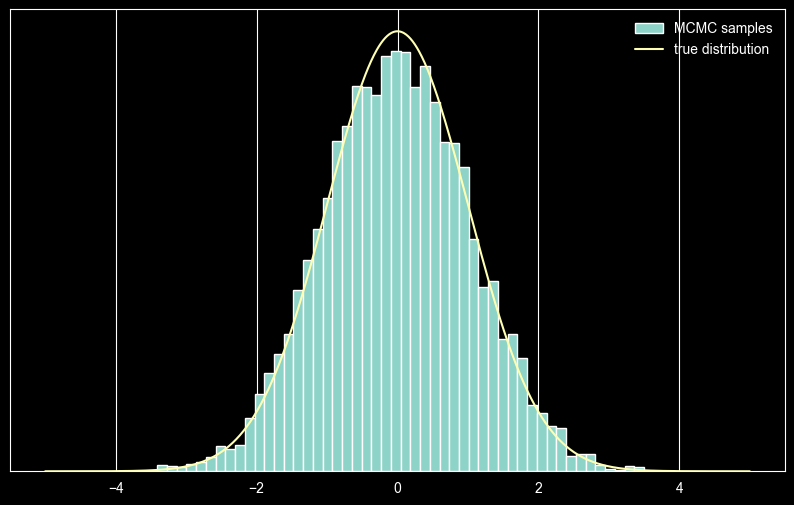

In [26]:
def plot_samples(chain, log_prob, ax, orientation='vertical',
                 xlims=(-5, 5), legend=True):
    from scipy.integrate import quad

    ax.hist(chain, bins=50, density=True, label="MCMC samples",
           orientation=orientation)
    # Normalize the comparison curve to the same probability-density scale
    # as the histogram. The MCMC sampler itself does not need this factor.
    normalization_factor, _ = quad(
        lambda x: np.exp(log_prob(x)), -np.inf, np.inf
    )
    xses = np.linspace(xlims[0], xlims[1], 1000)
    yses = [np.exp(log_prob(x)) / normalization_factor for x in xses]
    if orientation == 'horizontal':
        (yses, xses) = (xses, yses)
    ax.plot(xses, yses, label="true distribution")
    if legend:
        ax.legend(frameon=False)

fig, ax = plt.subplots()
plot_samples(chain[500:], log_prob, ax)
#despine(ax)
ax.set_yticks(())
plt.show()

## 6. Proposal width controls exploration

A proposal should move far enough to explore the target while avoiding excessive rejection. There is no universal acceptance rate that alone guarantees efficient sampling.

### Wide proposals: `stepsize = 30`

The candidate lies within $15$ units of the current state. Because the target has standard deviation one, many proposals land in low-density regions and are rejected. The chain often repeats its current value. The saved acceptance rate is about 0.10.

**Predict before running:** What would a trace plot of state versus iteration look like when there are many consecutive rejections?

Acceptance rate: 0.113


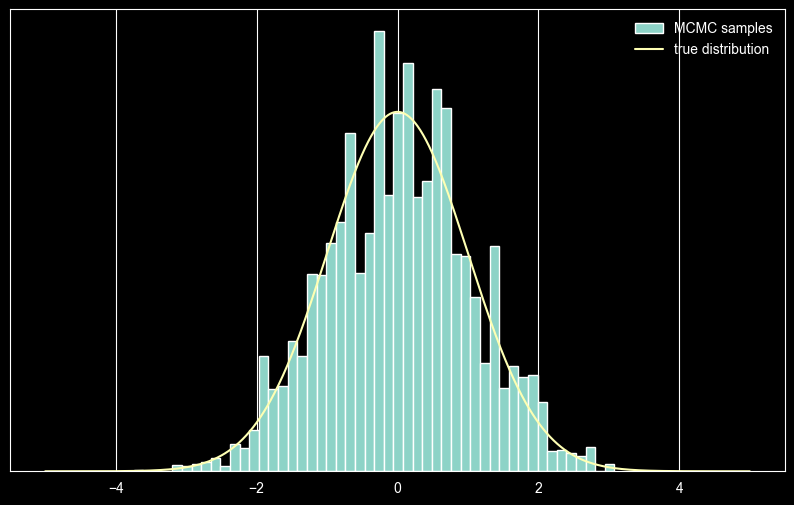

In [27]:
def sample_and_display(init_state, stepsize, n_total, n_burnin, log_prob):
    chain, acceptance_rate = build_MH_chain(init_state, stepsize, n_total, log_prob)
    print("Acceptance rate: {:.3f}".format(acceptance_rate))
    fig, ax = plt.subplots()
    plot_samples([state for state, in chain[n_burnin:]], log_prob, ax)
    #despine(ax)
    ax.set_yticks(())
    plt.show()

sample_and_display(np.array([2.0]), 30, 10000, 500, log_prob)

### Narrow proposals: `stepsize = 0.1`

Now each move is at most $0.05$ in magnitude. Nearby points usually have similar density, so most proposals are accepted. Nevertheless, the chain can take many steps to travel across the target distribution.

The saved acceptance rate near 0.99 is therefore not automatically better than the moderate-width run. High acceptance can coexist with strong autocorrelation and poor exploration over a finite run.

Acceptance rate: 0.984


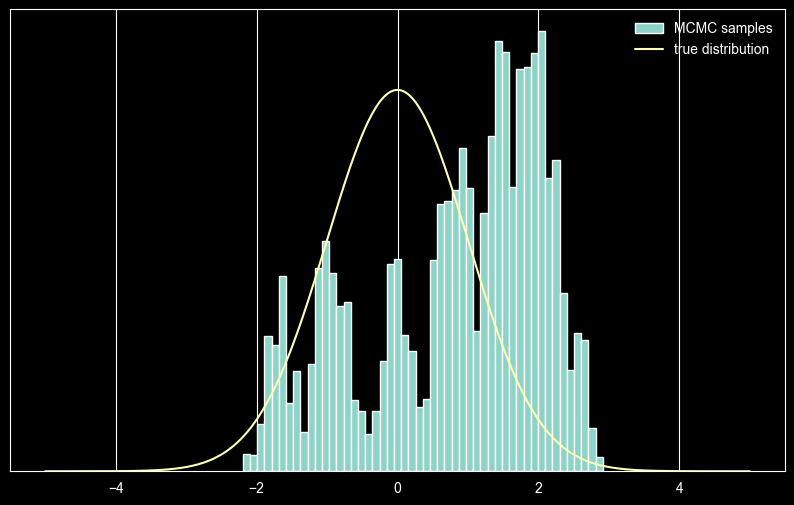

In [28]:
sample_and_display(np.array([2.0]), 0.1, 10000, 500, log_prob)


### A longer run with the same narrow proposal

The last experiment makes 500,000 proposals and discards 25,000 recorded states, leaving 475,001 observations. More iterations can improve estimates, but they do not change the underlying proposal's slow movement.

Compare the histogram with the shorter narrow-proposal run. Then ask whether a moderate proposal width could achieve similar precision with less computation. These runs change both total length and burn-in, so the plots alone do not isolate the effect of either choice.

Acceptance rate: 0.991


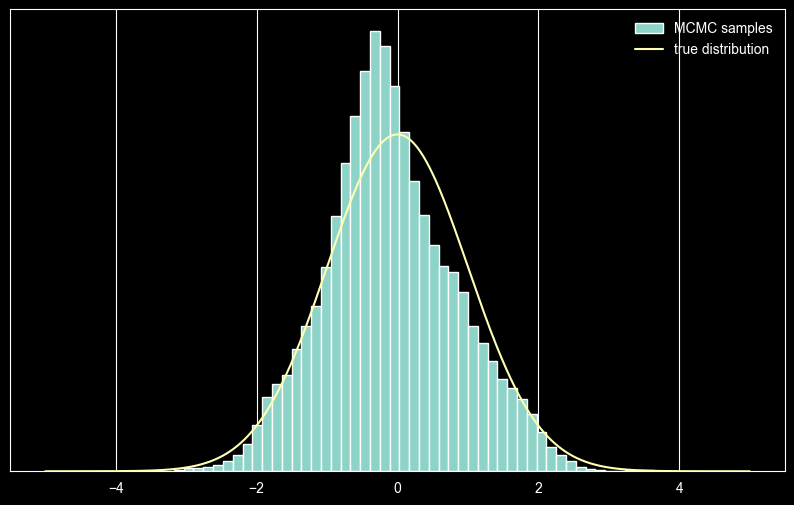

In [29]:
sample_and_display(np.array([2.0]), 0.1, 500000, 25000, log_prob)

### What did the stepsize investigation teach us?

The purpose of these simulations was not to find the stepsize with the highest acceptance rate. The stepsize controls a tradeoff between **how far the chain proposes to move** and **how often those proposals are accepted**.

- With `stepsize = 30`, proposed moves are usually much too large. Most land in regions where the Gaussian density is extremely small, so they are rejected. The chain repeatedly records the same state and explores inefficiently.
- With `stepsize = 0.1`, almost every proposal is accepted, but each move is tiny. Successive states are therefore very similar, and the chain moves slowly across the distribution. A high acceptance rate does not necessarily mean efficient sampling.
- Running the narrow-proposal chain for much longer eventually gives it more opportunity to explore, but this requires substantially more computation. More iterations can compensate for inefficient movement; they do not make the movement itself efficient.
- The moderate choice `stepsize = 3` provides a more useful balance in this example: proposed moves are large enough to explore the Gaussian while still being accepted often enough for the chain to keep moving.

All of these symmetric proposal widths define valid Metropolis--Hastings chains with the same Gaussian target. The difference is **efficiency**, not the target distribution. We want the chain to explore the important parts of the target with as little repeated or highly correlated information as possible.

This is also why neither a high acceptance rate nor a plausible-looking histogram is sufficient by itself. To judge the quality of an MCMC run, we must consider how strongly successive states are correlated and how much effectively independent information the chain contains. That is the subject of the next section.

## 7. Monte Carlo averages and correlated samples

Once initialization effects are negligible, a chain targeting $\pi$ can estimate an expectation using

$$\mu=\mathbb E_\pi[g(X)]=\int g(x)\pi(x)\,dx,
\qquad
\hat\mu_N=\frac1N\sum_{t=B}^{B+N-1}g(X_t),$$

where $B$ is the number of discarded states. For the standard Gaussian, useful checks are $g(x)=x$ with expectation zero and $g(x)=x^2$ with expectation one.

Successive samples are generally dependent. For the observable $g(X_t)$, define its stationary lag-$k$ autocorrelation as

$$\rho_g(k)=\frac{\operatorname{Cov}(g(X_t),g(X_{t+k}))}
{\operatorname{Var}_\pi(g(X))}.$$

Under conditions that give a Markov-chain central limit theorem and a convergent autocorrelation sum,

$$\tau_g=1+2\sum_{k=1}^{\infty}\rho_g(k),\qquad
N_{\mathrm{eff}}\approx\frac{N}{\tau_g},$$

$$\operatorname{SE}(\hat\mu_N)\approx
\sqrt{\frac{\operatorname{Var}_\pi(g(X))}{N_{\mathrm{eff}}}}.$$

The effective sample size depends on the observable: estimates of the mean and second moment need not have the same precision. Treating every stored state as independent can underestimate uncertainty when correlations are positive.

Burn-in addresses initialization; it does not eliminate correlation among the retained states. Keeping every $k$th state is called **thinning**, which may reduce correlation between stored observations but discards data and does not automatically improve precision per unit of computation. Plotting fewer points is a separate display choice.

## Lecture questions and extensions

1. **Verify stationarity.** Multiply $(7/18,1/3,5/18)$ by the weather transition matrix. Why is the result unchanged even though the simulated weather keeps changing?
2. **Challenge the convergence claim.** Consider $P=\begin{pmatrix}0&1\\1&0\end{pmatrix}$. It is row-stochastic and has stationary distribution $(1/2,1/2)$. What happens when the chain starts in state 0? Distinguish time-averaged occupation fractions from convergence of $\mathbf p_t$.
3. **Explain rejection.** Why would storing only accepted moves alter the residence time in each region? Relate your answer to the $r(x)\delta_x$ term in the transition kernel.
4. **Compare exploration.** For widths 0.1, 3, and 30, collect chains with the same proposal count and burn-in. Compare traces, histograms, acceptance rates, and estimates of $\mathbb E[X]$ and $\mathbb E[X^2]$. Repeat with several seeds.
5. **Vary initialization.** Start chains at $-10$, $0$, and $10$. Examine whether their post-burn-in behavior agrees; choosing a random initial state alone does not guarantee stationarity unless it is sampled from the target distribution.
6. **Estimate precision.** Compare autocorrelation and effective sample size for $g(x)=x$ across proposal widths. Which width provides the most effective observations for the same computational budget?

The weather example includes both occupation fractions and a state trace. For the Metropolis–Hastings examples, trace plots, autocorrelation estimates, and comparisons across starting points remain proposed extensions; the existing cells display histograms. Likewise, `sample_and_display` plots a chain but does not return it: use `build_MH_chain` to retain samples for these diagnostics.

The key connection is that Markov dynamics supply dependent samples, while Monte Carlo averaging turns those samples into estimates. A valid stationary target, adequate exploration, and an assessment of sampling uncertainty are all needed to interpret those estimates.
